# 11 — Clean outer-fold Does image uncertainty help prioritise review?

An image model produces a score between 0 and 1: higher means more strongly
ranked toward melanoma. **Uncertainty** here means how much that score varies
when we repeat prediction under specified changes. A high score and a high
uncertainty estimate answer different questions.

We test whether variation improves the order in which images are sent for
review, beyond simply sending the highest ordinary scores. The saved clean inference used each image's own outer-held-out B0
**checkpoint** (saved model weights), from a fresh fixed-duration refit. The
report loads exported predictions and receipts only: it does not rebuild a
network, choose an old best checkpoint or perform inference. An epoch is one pass through the fitting data.

These are **five-fold outer-held-out diagnostics**: each scored patient's
images were excluded from that checkpoint's fitting, recipe and duration selection.
This strengthens the original one-inner-split scope. Earlier development
exploration remains a limitation; uncertainty rankings still do not select a
clinical referral policy or final architecture. The reserved test comes last
and is never opened by this report.

The [historical three-epoch experiment](../archive/image_uncertainty_three_epoch_fold0.ipynb)
and its result files are preserved. Clean pass exports belong to `results/dedup_v1/uncertainty/b0_uncertainty_dedup_v1`;
executing this notebook regenerates only its separate clean presentation figures. See the [concept guide](../concepts.md)
when a term is unfamiliar.


**Deduplicated workflow adaptation.** This notebook uses the frozen `dedup_v1` development manifest and original patient assignments. It reads saved clean artifacts; executing it starts no training and does not load the reserved test. The original notebook is preserved as the presentation template: [13_image_uncertainty.ipynb](../Subset/13_image_uncertainty.ipynb).

**Genuine experiment-scope change:** clean matching outer-refit predictions
replace the historical one-inner-split selected checkpoint. Colours, referral
linestyles, two-panel convergence, five-bin reliability, histogram composition
and MC-circle/TTA-square intervals retain the original visual language.

## 1. Choose saved clean checkpoints explicitly

The clean inference receipts identify one fresh outer refit per preserved fold.
They record the exact run, recipe (training settings), selected fixed duration,
checkpoint hash (file fingerprint), source-image identities, deterministic
preparation and saved ordinary predictions. All five raw refits must complete
before full clean uncertainty is accepted. Missing or incompatible artifacts
stop verification rather than silently falling back to a historical model.

**Scope change:** the original selectable one-pilot checkpoint adapter is replaced
by recorded `b0_nested_dedup_v1` outer checkpoints. This is an explicit matching
clean inference scope, not automatic architecture selection. `SOURCE_RUN`,
architecture and recipe are provenance for every fold, not notebook settings
that trigger another inference run. The table below reads actual completion;
no checkpoint is loaded into a neural network by this notebook.

In [1]:
NOTEBOOK_STAGE = '11_image_uncertainty'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcdefaults()
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
FIGURE_DIR = ROOT / DIRECTORY / "figures" / "template_v3" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename, *, dpi=None):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=dpi or globals().get("ORIGINAL_EXPORT_DPI", 150), bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary

from melanoma_detection import dedup_notebook_images as image_docs
image_docs.original_style('uncertainty')
uncertainty = image_docs.load_uncertainty(ROOT, dataset_identity)

# Preserve the original notebook's plotting defaults.
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white', 'axes.facecolor': 'white'})
ORIGINAL_EXPORT_DPI = 150


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

,status,images,patients,malignant_images,malignant_patients,mc_passes,tta_passes,training_fits
0,complete,6706,422,127,88,30,4,0


## 2. Recover the exact evaluation patients

Use the frozen retained development manifest and every preserved outer fold.
Each image receives prediction from its own outer-held-out checkpoint; no
patient occurs in that checkpoint's fitting or inner selection membership.
Patient IDs define separation and bootstrap groups; they are not model inputs.
Recorded identities and receipts bind source images, checkpoint bytes and the
ordinary prediction export, rather than recreating a newly sampled split.

The clean cohort contains 6,706 images from 422 patients, including 127 malignant
images from 88 patients with malignancy. **Scope change:** these replace the
historical weak-control pilot's 1,834 validation images from 113 patients.
Outer fold 0 is now scored by its matching outer refit rather than excluded
from the uncertainty report. Reserved-test tables and images remain outside
the loader and every diagnostic shown here.

In [2]:
image_docs.uncertainty_checks(uncertainty)

,image_id,patient_id,fold,target,base_score,mc_mean_score,mc_score_sd,tta_mean_score,tta_score_sd
0,ISIC_0015719,IP_3075186,0,0,0.000130,0.000156,0.000076,0.000112,0.000040
1,ISIC_0074542,IP_4698288,1,0,0.000133,0.000143,0.000053,0.000137,0.000019
2,ISIC_0076545,IP_9802602,2,0,0.017711,0.017909,0.003248,0.020957,0.002302
3,ISIC_0082348,IP_7684360,0,0,0.000249,0.000266,0.000095,0.000282,0.000067
4,ISIC_0085172,IP_1705144,1,0,0.000010,0.000010,0.000006,0.000015,0.000004
5,ISIC_0086349,IP_2825529,2,0,0.008073,0.008435,0.002625,0.007279,0.001150
6,ISIC_0086632,IP_2114130,4,0,0.000098,0.000124,0.000103,0.000095,0.000005
7,ISIC_0087297,IP_5389392,4,0,0.000059,0.000070,0.000041,0.000060,0.000006


,all_protected_files_unchanged,batchnorm_buffers_checked,batchnorm_buffers_unchanged,checkpoint_compatibility,evaluation_image_hashes_verified,fold,identity_tta_agreement,model_state_unchanged,only_explicit_dropout_active,patient_separation,protected_files_checked,saved_prediction_max_abs_difference,saved_predictions_agree,trained_dropout_rate_preserved
0,True,147,True,True,1344,0,True,True,True,True,8,1.110223e-16,True,True
1,True,147,True,True,1366,1,True,True,True,True,8,9.985502e-17,True,True
2,True,147,True,True,1328,2,True,True,True,True,8,9.974660e-17,True,True
3,True,147,True,True,1371,3,True,True,True,True,8,9.955686e-17,True,True
4,True,147,True,True,1297,4,True,True,True,True,8,1.110223e-16,True,True


,images,patients,malignant_images,expected_MC_rows,expected_TTA_rows
fold,,,,,
0,1344,84,24,40320,5376
1,1366,84,26,40980,5464
2,1328,87,26,39840,5312
3,1371,82,25,41130,5484
4,1297,85,26,38910,5188


,Total MC rows,Total TTA rows,Cutoff fitting,Calibration fitting,BN updates,Referral score
0,201180,26824,False,False,False,Frozen deterministic saved score


## 3. Check a small sample before full inference

The smoke check uses 16 images to catch a mismatch before a costly full run.
Deterministic predictions must repeat and agree with the saved export. Two
seeded dropout passes must vary under different seeds and repeat under the same
seed. Only explicit dropout may activate; BatchNorm buffers and all model state
must stay unchanged. Identity TTA (no image change) must reproduce the ordinary
score. Any failure stopped the separate clean inference runner before its 30-pass run.
This notebook reads its recorded smoke checks; it does not rerun inference or
mutate model state. The completed receipts are shown below when available.


In [3]:
if uncertainty['complete']:
    display(pd.DataFrame(read_json(uncertainty['directory'] / 'inference_checks.json')['folds']))

,all_protected_files_unchanged,batchnorm_buffers_checked,batchnorm_buffers_unchanged,checkpoint_compatibility,evaluation_image_hashes_verified,fold,identity_tta_agreement,model_state_unchanged,only_explicit_dropout_active,patient_separation,protected_files_checked,saved_prediction_max_abs_difference,saved_predictions_agree,trained_dropout_rate_preserved
0,True,147,True,True,1344,0,True,True,True,True,8,1.110223e-16,True,True
1,True,147,True,True,1366,1,True,True,True,True,8,9.985502e-17,True,True
2,True,147,True,True,1328,2,True,True,True,True,8,9.974660e-17,True,True
3,True,147,True,True,1371,3,True,True,True,True,8,9.955686e-17,True,True
4,True,147,True,True,1297,4,True,True,True,True,8,1.110223e-16,True,True


### Inspect the four conservative views

**Read the preview:** each row is one prepared image; columns are identity,
horizontal flip, vertical flip and both flips. `target=0` is benign, `target=1`
malignant. Check that the whole lesion, texture and colour remain visible; only
orientation should change. These operations rearrange pixels without deleting
them or creating reflected border fragments. One example from each class shows
framing, not representative prevalence. Labels do not choose transformations.


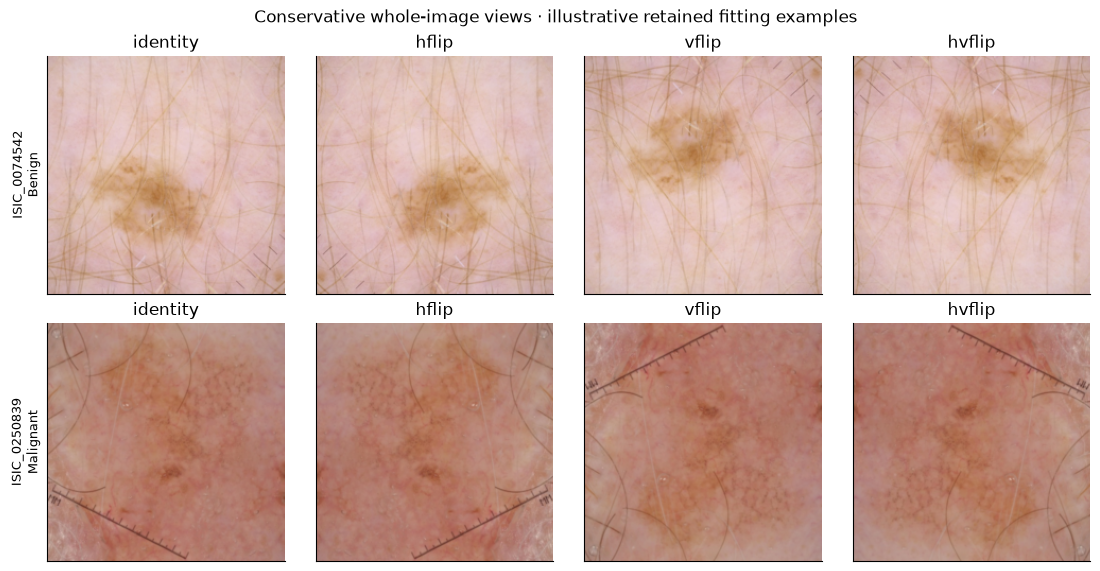

In [4]:
image_docs.uncertainty_views(ROOT, data, dataset_identity, finish_figure)

## 4. Keep dropout variation and image-view variation separate

**MC dropout** (Monte Carlo dropout) predicts the same prepared image 30 times.
Dropout randomly disables some activations, creating a different mask each pass.
Only explicit dropout layers activate at their trained rate (0.2 here).
BatchNorm, which keeps learned normalisation statistics, and stochastic depth,
which can randomly bypass network blocks, stay in evaluation mode. Every pass
has a recorded seed. The mean is an ensemble **prediction score**; sample
standard deviation (**SD**, denominator 29) measures spread under those masks.
It does not capture all sources of uncertainty.

**TTA** (test-time augmentation) instead keeps the whole model in evaluation
mode and averages four views: identity, horizontal, vertical and both flips.
They act on the exact prepared tensor after whole-image resize and any recorded
preprocessing. No crop, padding, arbitrary rotation or colour change is added.
Flips preserve pixels and can be applied after normalisation without changing
their values. Sample SD (denominator 3) measures orientation sensitivity for
these four views, not uncertainty across every plausible image change. Its
numerical size cannot be compared with dropout SD as total uncertainty.

Sigmoid converts the network output to a score in [0,1]. These scores and their
means are **not calibrated probabilities**: class weighting can change their
scale. No score-to-probability mapping or decision threshold is fitted here.


In [5]:
display(pd.DataFrame([{'mode':'MC dropout', 'passes':30, 'seed':20261004, 'stochastic component':'trained explicit dropout only'}, {'mode':'TTA', 'passes':4, 'seed':20261004, 'stochastic component':'none; deterministic tensor flips'}]))

,mode,passes,seed,stochastic component
0,MC dropout,30,20261004,trained explicit dropout only
1,TTA,4,20261004,none; deterministic tensor flips


## 5. Validate before aggregation

Each raw row is one image and one pass/view. The validator rejects NaN, infinity,
scores outside [0,1], repeated image/pass keys, extra images or passes, changed
patient IDs/labels, and incomplete passes or image coverage. Only complete,
validated raw predictions enter a summary. The saved raw tables allow every
mean and SD to be independently recomputed.


In [6]:
image_docs.uncertainty_checks(uncertainty)

,image_id,patient_id,fold,target,base_score,mc_mean_score,mc_score_sd,tta_mean_score,tta_score_sd
0,ISIC_0015719,IP_3075186,0,0,0.000130,0.000156,0.000076,0.000112,0.000040
1,ISIC_0074542,IP_4698288,1,0,0.000133,0.000143,0.000053,0.000137,0.000019
2,ISIC_0076545,IP_9802602,2,0,0.017711,0.017909,0.003248,0.020957,0.002302
3,ISIC_0082348,IP_7684360,0,0,0.000249,0.000266,0.000095,0.000282,0.000067
4,ISIC_0085172,IP_1705144,1,0,0.000010,0.000010,0.000006,0.000015,0.000004
5,ISIC_0086349,IP_2825529,2,0,0.008073,0.008435,0.002625,0.007279,0.001150
6,ISIC_0086632,IP_2114130,4,0,0.000098,0.000124,0.000103,0.000095,0.000005
7,ISIC_0087297,IP_5389392,4,0,0.000059,0.000070,0.000041,0.000060,0.000006


,all_protected_files_unchanged,batchnorm_buffers_checked,batchnorm_buffers_unchanged,checkpoint_compatibility,evaluation_image_hashes_verified,fold,identity_tta_agreement,model_state_unchanged,only_explicit_dropout_active,patient_separation,protected_files_checked,saved_prediction_max_abs_difference,saved_predictions_agree,trained_dropout_rate_preserved
0,True,147,True,True,1344,0,True,True,True,True,8,1.110223e-16,True,True
1,True,147,True,True,1366,1,True,True,True,True,8,9.985502e-17,True,True
2,True,147,True,True,1328,2,True,True,True,True,8,9.974660e-17,True,True
3,True,147,True,True,1371,3,True,True,True,True,8,9.955686e-17,True,True
4,True,147,True,True,1297,4,True,True,True,True,8,1.110223e-16,True,True


,images,patients,malignant_images,expected_MC_rows,expected_TTA_rows
fold,,,,,
0,1344,84,24,40320,5376
1,1366,84,26,40980,5464
2,1328,87,26,39840,5312
3,1371,82,25,41130,5484
4,1297,85,26,38910,5188


,Total MC rows,Total TTA rows,Cutoff fitting,Calibration fitting,BN updates,Referral score
0,201180,26824,False,False,False,Frozen deterministic saved score


## 6. Check stability as the number of passes increases

Compare the first 5, 10 and 20 seeded passes with the same 30-pass reference;
labels do not select the pass count. **Read the two panels:** pass count is
horizontal. Left, mean absolute difference from the reference is vertical,
with separate solid/ dashed lines for mean score and SD for each preserved fold; closer to zero means more stable
values. Right, SD rank correlation is vertical; closer to 1 means a more similar
ordering of images. The table also gives overlap among the highest-SD 20%. Fold colours identify
the five different held-out checkpoints; the original two-panel composition
and numerical-versus-ranking distinction are retained.

Stable scores need not imply stable rankings. The finite 30-pass reference is
not an exact expectation, so agreement is evidence of stability rather than
proof that all uncertainty has been captured.


,n_passes,reference_passes,mean_score_mae,score_sd_mae,sd_spearman,top20_overlap_fraction,fold
0,5,30,0.001191,0.001018,0.979092,0.914498,0
1,10,30,0.000751,0.000606,0.991070,0.951673,0
2,20,30,0.000385,0.000279,0.997707,0.977695,0
3,5,30,0.000740,0.000749,0.982927,0.894161,1
4,10,30,0.000442,0.000420,0.992714,0.930657,1
5,20,30,0.000228,0.000215,0.998229,0.970803,1
6,5,30,0.000671,0.000592,0.969093,0.906015,2
7,10,30,0.000448,0.000349,0.986593,0.928571,2
8,20,30,0.000218,0.000180,0.995896,0.969925,2
9,5,30,0.000239,0.000257,0.981947,0.894545,3


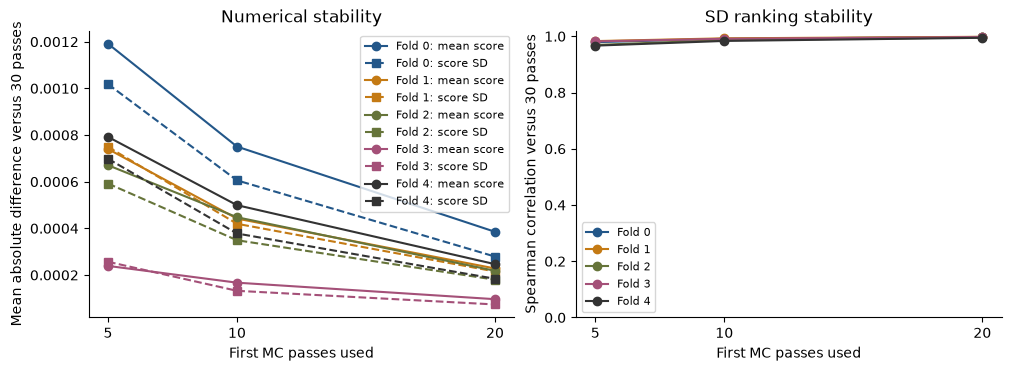

In [7]:
image_docs.uncertainty_convergence(uncertainty, finish_figure)

## 7. Compare ranking and descriptive reliability

**AP** (average precision) summarises precision (malignancy among flags) as
recall (malignant images found) changes with the cutoff; higher is better.
It is useful for rare malignancies. **ROC-AUC** summarises overall ranking;
higher is better and 0.5 is chance. **Log loss** penalises confident wrong scores
and **Brier** averages squared score errors; lower is better, but both can hide
poor recall when benign images dominate. The fitting-prevalence constant is a
simple baseline computed without validation labels, not a fitted calibrator.

**Read the reliability diagram:** each line is deterministic, MC mean or TTA
mean. Up to five equal-count bins group similar scores. Horizontal position is
the bin's mean score, vertical position its observed malignant-image fraction.
The diagonal means agreement; below it scores exceed the observed frequency,
above it scores fall below it. Left shows [0,1]; right enlarges the same observed
range and bins. A point near the diagonal is descriptive agreement, not proof
of calibrated clinical risk. Bin support is saved; sparse malignancies and
patients contributing to several bins make the estimates noisy. Each checkpoint's duration was chosen within its own training patients.
**Scope change:** these pooled diagrams use matching clean outer-held-out
predictions, while unweighted mean-fold AP/AUC remain primary. The earlier
pilot/development adaptations still limit the independence of final claims.


,fold,mode,images,patients,malignant_images,average_precision,roc_auc,log_loss,brier
0,0,deterministic,1344,84,24,0.152537,0.854419,0.095513,0.022482
1,0,mc,1344,84,24,0.154791,0.856660,0.094917,0.022484
2,0,tta,1344,84,24,0.139996,0.851010,0.093828,0.022084
3,1,deterministic,1366,84,26,0.148876,0.839179,0.090245,0.019154
4,1,mc,1366,84,26,0.154862,0.837887,0.090163,0.019183
5,1,tta,1366,84,26,0.139101,0.847130,0.088172,0.019063
6,2,deterministic,1328,87,26,0.148730,0.864823,0.082345,0.018674
7,2,mc,1328,87,26,0.149296,0.866507,0.081756,0.018637
8,2,tta,1328,87,26,0.135721,0.858768,0.083377,0.018691
9,3,deterministic,1371,82,25,0.057262,0.757266,0.138206,0.018364


,mode,average_precision,roc_auc,log_loss,brier
0,deterministic,0.131570,0.830801,0.099116,0.019637
1,mc,0.133261,0.830044,0.098709,0.019634
2,tta,0.125830,0.830146,0.097910,0.019443
3,constant fitting prevalence,0.018950,0.500000,0.093934,0.018591


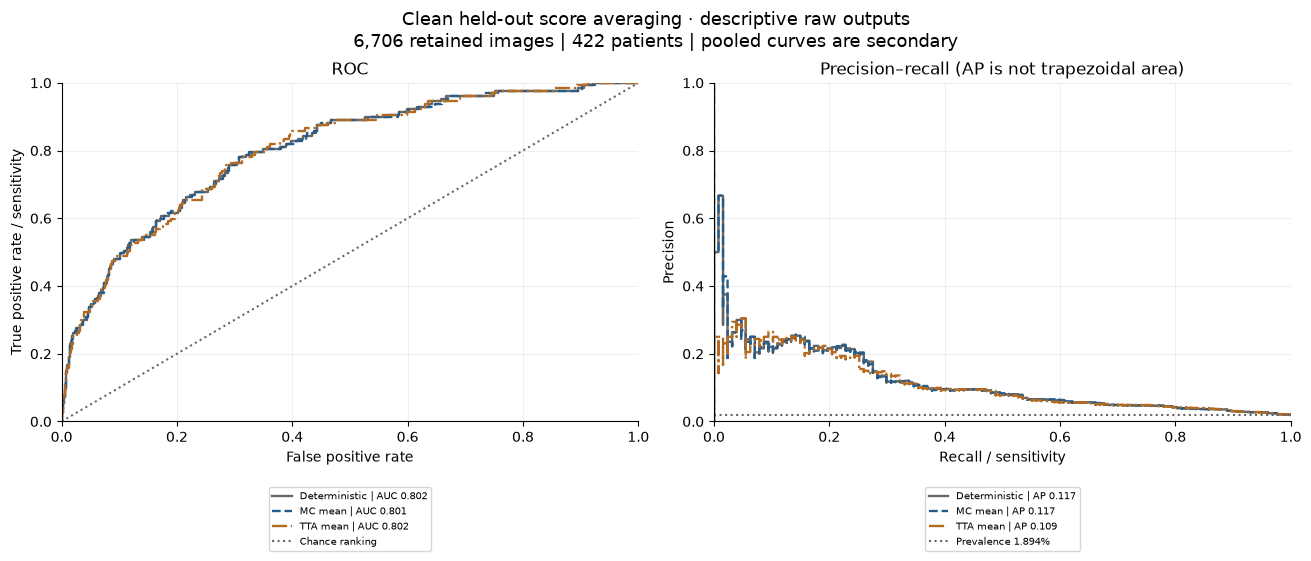

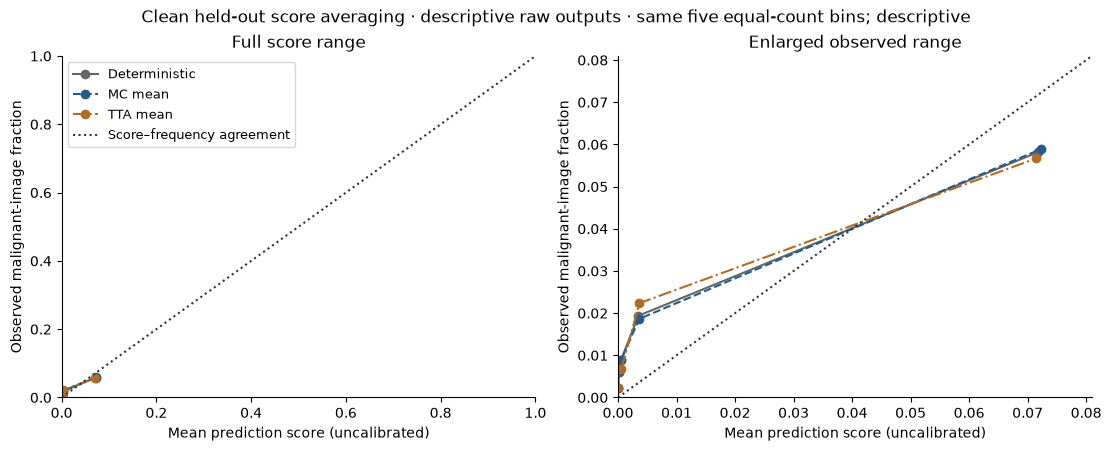

,bin,n_images,n_malignant_images,mean_probability,observed_rate,min_probability,max_probability,n_patients,model
0,1,1342,3,0.000017,0.002235,2.590740e-09,0.000050,164,Deterministic
1,2,1341,8,0.000110,0.005966,4.980170e-05,0.000201,217,Deterministic
2,3,1341,12,0.000517,0.008949,2.014816e-04,0.001118,286,Deterministic
3,4,1341,26,0.003487,0.019389,1.118944e-03,0.007783,329,Deterministic
4,5,1341,78,0.071764,0.058166,7.784358e-03,0.991087,309,Deterministic
5,1,1342,3,0.000020,0.002235,3.499143e-09,0.000056,163,MC mean
6,2,1341,8,0.000121,0.005966,5.578612e-05,0.000222,218,MC mean
7,3,1341,12,0.000552,0.008949,2.226003e-04,0.001164,285,MC mean
8,4,1341,25,0.003622,0.018643,1.164211e-03,0.008130,329,MC mean
9,5,1341,79,0.072296,0.058911,8.133079e-03,0.989629,307,MC mean


In [8]:
image_docs.uncertainty_quality(uncertainty, data, finish_figure)

## 8. Examine what the two SD measures capture

**Read the histograms:** the left panel bins MC score SD and the middle bins
TTA score SD horizontally; vertical height counts images. Mass near zero means
little change under that procedure. Each panel has its own SD scale because
dropout masks and image orientations perturb different things.

**Read the scatterplot:** each dot is an image, with MC SD horizontally and
TTA SD vertically. A rising pattern suggests the methods prioritise similar
images; scatter suggests different sensitivities. There is no equal-SD target
because the measures have different meanings. Variation does not prove malignancy
or error, and a model can be consistently, confidently wrong.


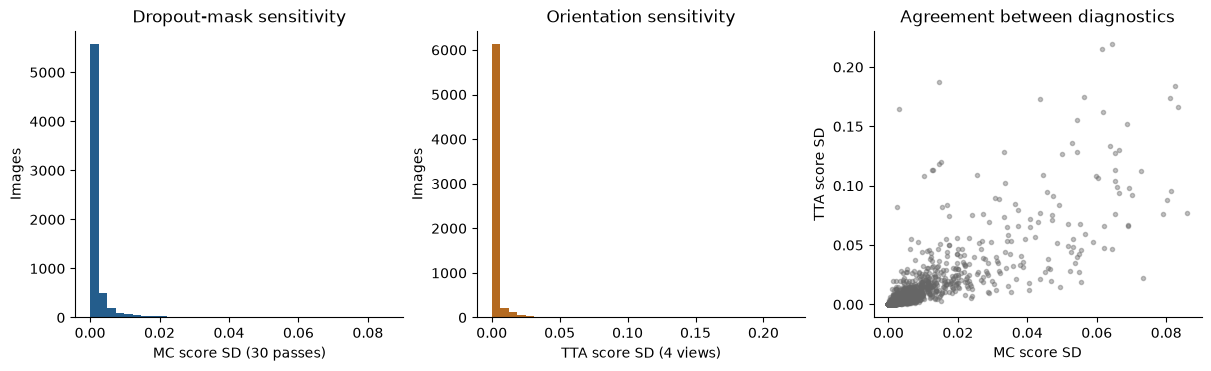

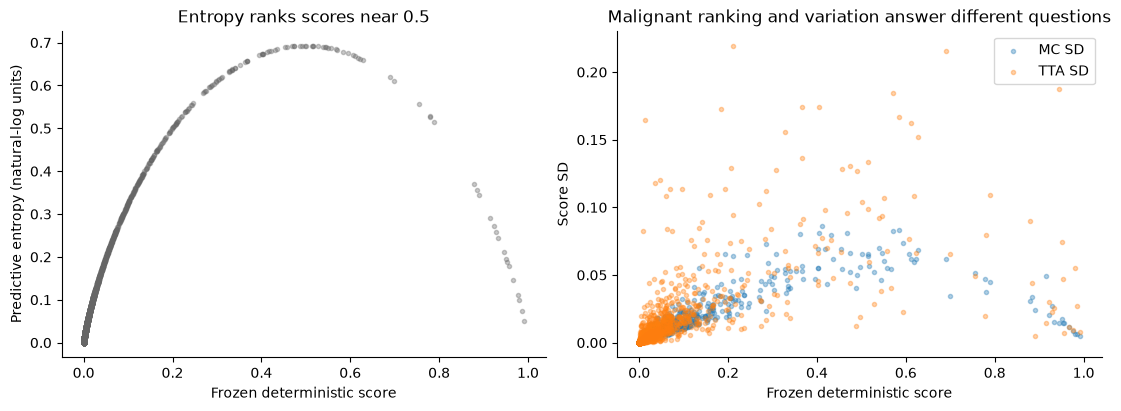

In [9]:
image_docs.uncertainty_distributions(uncertainty, finish_figure)

## 9. Does SD improve the referral order?

**Referral** means setting some images aside for review. The **retained set**
contains those still evaluated automatically. All rankings use the **same
deterministic predictions**, labels and predeclared referral fractions, so the
comparison isolates ranking rather than MC/TTA score averaging.

Rank from highest to lowest by SD, ordinary score, or predictive entropy
`−s log(s) − (1−s) log(1−s)`. Score ranking prioritises stronger melanoma scores;
entropy prioritises scores near 0.5, where the binary score is least decisive.
Entropy inherits the uncalibrated score scale. Random referral is repeated with
100 recorded seeds to give a simple baseline. Ties use image ID; no operational
fraction is selected from these labels.

Retained classification error uses the fixed descriptive cutoff 0.5; MAE
(mean absolute score error) and Brier also expose score errors. Malignant images
referred and distinct patients with a malignant image referred have different
denominators. Referral acts on images, not every image from a patient, and it
does not simulate whether a reviewer diagnoses correctly.

**Read the four panels:** the top row uses MC SD, the bottom TTA SD. Horizontal
position is percentage of all images referred. Left is retained classification
error (lower is better); right is percentage of malignant images referred
(higher is better). Lines compare SD, ordinary score, entropy and mean random
referral at the same budget. Compare at the same horizontal position; a lower
left curve alone may hide which malignant cases remain. These curves describe
trade-offs, not a selected clinical policy.


In [10]:
if uncertainty['complete']:
    display(pd.read_csv(uncertainty['directory'] / 'referral_rankings.csv'))

,method,ranking,random_seed,referral_fraction,score_column,fixed_score_cutoff,n_images,n_patients,n_malignant_images,n_malignant_patients,...,n_retained,n_patients_referred,n_patients_retained,retained_error,retained_brier,retained_score_mae,n_malignant_images_referred,malignant_referred_fraction,n_malignant_patients_referred,malignant_patients_referred_fraction
0,mc,uncertainty_sd,NaN,0.00,base_score,0.5,6706,422,127,88,...,6706,0,422,0.022368,0.019634,0.029693,0,0.000000,0,0.000000
1,mc,uncertainty_sd,NaN,0.05,base_score,0.5,6706,422,127,88,...,6371,157,418,0.013970,0.013718,0.017913,38,0.299213,27,0.306818
2,mc,uncertainty_sd,NaN,0.10,base_score,0.5,6706,422,127,88,...,6036,227,409,0.011431,0.011316,0.013844,58,0.456693,39,0.443182
3,mc,uncertainty_sd,NaN,0.20,base_score,0.5,6706,422,127,88,...,5365,309,387,0.009320,0.009278,0.010355,77,0.606299,52,0.590909
4,mc,uncertainty_sd,NaN,0.30,base_score,0.5,6706,422,127,88,...,4695,354,347,0.006816,0.006803,0.007276,95,0.748031,66,0.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1437,tta,random,17141.0,0.10,base_score,0.5,6706,422,127,88,...,6036,277,422,0.023194,0.020459,0.030663,9,0.070866,9,0.102273
1438,tta,random,17141.0,0.20,base_score,0.5,6706,422,127,88,...,5365,363,419,0.022554,0.019898,0.030138,27,0.212598,24,0.272727
1439,tta,random,17141.0,0.30,base_score,0.5,6706,422,127,88,...,4695,397,417,0.022577,0.020026,0.030138,38,0.299213,35,0.397727
1440,tta,random,17141.0,0.40,base_score,0.5,6706,422,127,88,...,4024,409,414,0.022863,0.020213,0.030309,52,0.409449,45,0.511364


,method,ranking,n_images,n_patients,n_malignant_images,n_malignant_patients,n_referred,n_malignant_images_referred,n_malignant_patients_referred,retained_error,malignant_referred_fraction
3,mc,uncertainty_sd,6706,422,127,88,1341,77,52,0.009320,0.606299
10,mc,prediction_score,6706,422,127,88,1341,78,53,0.009133,0.614173
17,mc,predictive_entropy,6706,422,127,88,1341,78,53,0.009133,0.614173
724,tta,uncertainty_sd,6706,422,127,88,1341,79,55,0.008947,0.622047
731,tta,prediction_score,6706,422,127,88,1341,78,53,0.009133,0.614173
738,tta,predictive_entropy,6706,422,127,88,1341,78,53,0.009133,0.614173


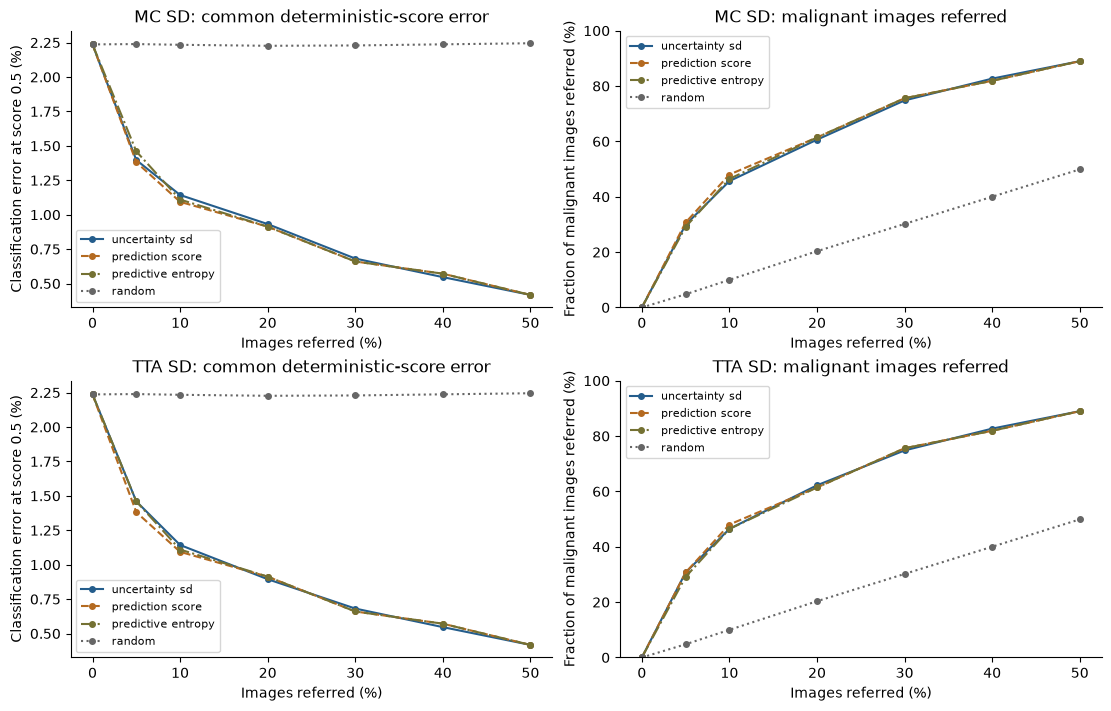

,fold,method,ranking,n_images,n_patients,n_malignant_images,n_malignant_patients,n_referred,n_malignant_images_referred,n_malignant_patients_referred,retained_error,malignant_referred_fraction
3,0,mc,uncertainty_sd,1344,84,24,17,268,15,9,0.008364,0.625000
724,0,tta,uncertainty_sd,1344,84,24,17,268,14,9,0.009294,0.583333
1445,1,mc,uncertainty_sd,1366,84,26,15,273,16,8,0.009149,0.615385
2166,1,tta,uncertainty_sd,1366,84,26,15,273,17,10,0.008234,0.653846
2887,2,mc,uncertainty_sd,1328,87,26,21,265,21,17,0.004704,0.807692
3608,2,tta,uncertainty_sd,1328,87,26,21,265,19,15,0.006585,0.730769
4329,3,mc,uncertainty_sd,1371,82,25,18,274,13,11,0.010939,0.520000
5050,3,tta,uncertainty_sd,1371,82,25,18,274,10,7,0.013674,0.400000
5771,4,mc,uncertainty_sd,1297,85,26,17,259,16,12,0.009634,0.615385
6492,4,tta,uncertainty_sd,1297,85,26,17,259,18,13,0.007707,0.692308


In [11]:
image_docs.uncertainty_referral(uncertainty, finish_figure)

## 10. Estimate paired differences with patient bootstrap intervals

The **patient bootstrap** repeatedly samples whole patient groups with
replacement, keeping each patient's images together. We use 2,000 resamples of
the original number of retained patients independently within each of the five outer folds and recompute referral rankings and budgets each
time. This respects dependence between images of the same patient. Differences
are SD ranking minus score, entropy or mean random ranking on the same resample.
Undefined malignant fractions in resamples without malignancy remain missing;
valid replicate counts are reported.

**Read the interval plot at the predeclared 20% referral:** each row names the
method and comparator. Dots/squares are paired estimates, horizontal bars are
95% percentile intervals; blue circles are MC and orange squares TTA. Horizontal
units are percentage-point differences. The dotted zero line means no difference.
On the left, negative retained-error differences favour SD; on the right,
positive malignant-referral differences favour SD. An interval crossing zero
includes no difference and should not be read as clear evidence of benefit.

Intervals describe uncertainty conditional on these fitted predictions and
finite masks/views. They omit training-seed variation and do not include retraining or repeat the recipe/duration selection process,
and do not undo earlier development adaptation. Testing several fractions also creates
multiple comparisons; a favourable point does not establish a referral policy.


In [12]:
if uncertainty['complete']:
    display(pd.read_csv(uncertainty['directory'] / 'paired_patient_bootstrap_differences.csv'))

,method,ranking,comparator,score_column,referral_fraction,metric,estimate,ci_lower,ci_upper,n_requested,n_valid,n_undefined,n_random_per_replicate,bootstrap_seed,referral_seed,resampling
0,mc,uncertainty_sd,prediction_score,base_score,0.00,retained_error,0.000000,0.000000,0.000000,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
1,mc,uncertainty_sd,prediction_score,base_score,0.00,malignant_referred_fraction,0.000000,0.000000,0.000000,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
2,mc,uncertainty_sd,prediction_score,base_score,0.05,retained_error,0.000157,-0.000480,0.001147,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
3,mc,uncertainty_sd,prediction_score,base_score,0.05,malignant_referred_fraction,-0.007874,-0.058824,0.024799,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
4,mc,uncertainty_sd,prediction_score,base_score,0.10,retained_error,0.000497,-0.000485,0.001328,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,tta,uncertainty_sd,random,base_score,0.30,malignant_referred_fraction,0.446142,0.336214,0.532267,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
80,tta,uncertainty_sd,random,base_score,0.40,retained_error,-0.016906,-0.021822,-0.012485,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
81,tta,uncertainty_sd,random,base_score,0.40,malignant_referred_fraction,0.426614,0.331260,0.499673,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
82,tta,uncertainty_sd,random,base_score,0.50,retained_error,-0.018276,-0.023567,-0.013508,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds


,method,ranking,comparator,score_column,referral_fraction,metric,estimate,ci_lower,ci_upper,n_requested,n_valid,n_undefined,n_random_per_replicate,bootstrap_seed,referral_seed,resampling
6,mc,uncertainty_sd,prediction_score,base_score,0.2,retained_error,0.000186,-0.000557,0.001310,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
7,mc,uncertainty_sd,prediction_score,base_score,0.2,malignant_referred_fraction,-0.007874,-0.052241,0.024194,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
20,mc,uncertainty_sd,predictive_entropy,base_score,0.2,retained_error,0.000186,-0.000568,0.001162,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
21,mc,uncertainty_sd,predictive_entropy,base_score,0.2,malignant_referred_fraction,-0.007874,-0.052632,0.024194,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
34,mc,uncertainty_sd,random,base_score,0.2,retained_error,-0.012947,-0.017360,-0.009090,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
35,mc,uncertainty_sd,random,base_score,0.2,malignant_referred_fraction,0.402992,0.297141,0.505934,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
48,tta,uncertainty_sd,prediction_score,base_score,0.2,retained_error,-0.000186,-0.001138,0.001399,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
49,tta,uncertainty_sd,prediction_score,base_score,0.2,malignant_referred_fraction,0.007874,-0.059709,0.049597,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
62,tta,uncertainty_sd,predictive_entropy,base_score,0.2,retained_error,-0.000186,-0.001142,0.001288,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds
63,tta,uncertainty_sd,predictive_entropy,base_score,0.2,malignant_referred_fraction,0.007874,-0.060000,0.049597,2000,2000,0,100,20242,17042,whole_patients_within_outer_folds


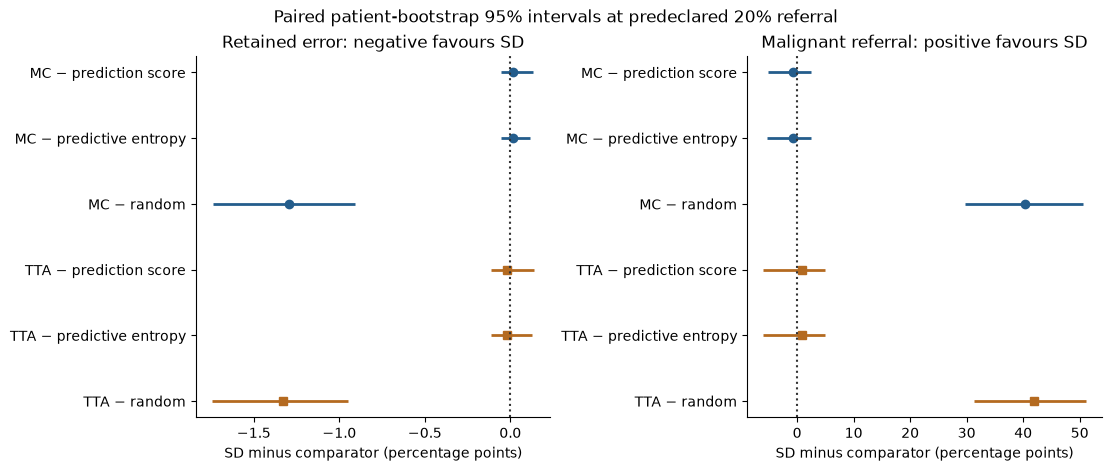

At the predeclared 20% referral, **4 of 4** displayed intervals against score ranking include zero. Read the direction and support counts; these conditional intervals do not establish a clinical policy or a final architecture.

In [13]:
image_docs.uncertainty_intervals(uncertainty, finish_figure)

## 11. Preserve the training artifacts and record provenance

File hashes compare checkpoints, histories, old prototype outputs and the
historical notebook in the saved before/after inference receipts. We also retain the checkpoint
and split identities, deterministic preprocessing profile, all pass seeds,
batch size, device and package versions, referral seeds/fractions, bootstrap
settings and the current inference source hashes. Raw and summary outputs belong only to the clean inference directory.
Figure outputs belong to this notebook's separate clean report directory;
no source checkpoint, saved raw pass or historical result is overwritten.


In [14]:
if uncertainty['complete']:
    display(pd.DataFrame([{key: uncertainty['receipt'][key] for key in ('dataset_manifest_sha256','bootstrap_sampling','referral_score','test_set_loaded','calibration_fitted','cutoff_fitted')}]))

,dataset_manifest_sha256,bootstrap_sampling,referral_score,test_set_loaded,calibration_fitted,cutoff_fitted
0,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...,whole_patients_within_outer_folds,frozen_saved_deterministic_base_score,False,False,False


## Limitations

This is a complete but imbalanced retained five-fold development cohort.
Each scored patient is excluded from its own checkpoint's recipe/duration
selection, and direct training leakage is checked. Earlier development pilots
and model exploration mean this still cannot replace an independent final test. Neither a favourable
architecture AP nor a favourable referral fraction selects the final model.

Dropout SD covers explicit dropout-mask variation only. It excludes backbone
stochastic depth, training-seed variation and distribution shift. TTA covers four
conservative orientations only; it does not estimate total uncertainty. Thirty
passes are a finite reference, and rank convergence can be slower than score
convergence. Low uncertainty can accompany consistent errors.

The class-weighted scores are uncalibrated. Reliability bins have sparse
malignant support, and image-level referral does not establish patient-level
clinical benefit. The fixed cutoff 0.5 is descriptive. Bootstrap intervals are
conditional and do not correct selection optimism or multiple comparisons.
No calibrator, selected clinical referral threshold, fusion model or reserved
test evaluation is implemented by this report. The separate clean calibration
stage remains distinct from these raw-score uncertainty diagnostics.

## Summary

The current workflow attaches uncertainty to the explicitly recorded matching
outer-refit checkpoints, reproduces its exact preparation and patient membership, and
checks inference without changing training artifacts. Raw scores, MC means/SDs
and TTA means/SDs are kept separate and saved with provenance. The executed
summary below reports the observed prediction metrics; the referral tables and
paired intervals determine whether SD adds useful information on the retained outer-held-out records.
All findings remain conditional development diagnostics. The numerical recap
uses saved clean results; an unchanged frozen procedure and the independently
reserved test remain necessary before claiming final generalisation.


In [15]:
image_docs.uncertainty_takeaways(uncertainty)

,mode,average_precision,roc_auc,log_loss,brier
0,deterministic,0.131570,0.830801,0.099116,0.019637
1,mc,0.133261,0.830044,0.098709,0.019634
2,tta,0.125830,0.830146,0.097910,0.019443


**Executed clean scope:** 6,706 retained outer-held-out images from 422 patients. At the prescribed 20% referral, **4 of 4** SD-minus-score intervals include zero. Read both retained errors and malignant referral support before claiming an ordering benefit. A favourable mean prediction or conditional interval does not establish a clinical referral policy; the reserved test remains outside this report.